# Gradient Descent and Newton Methods

**AI Mathematics · 5. Optimization**

Learn optimization objectives, gradient descent updates, learning-rate effects, and the role of second-order curvature.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Write an optimization objective and its gradient.
- Run gradient descent and monitor convergence.
- Compare first- and second-order methods.

In [1]:
import numpy as np

## 1. Optimization setup
Optimization minimizes an objective \(L(\theta)\) over parameters. Gradient descent updates \(\theta_{t+1}=\theta_t-\eta\nabla L(\theta_t)\). The learning rate \(\eta\) controls step size: too small is slow, too large may diverge.

In [2]:
import numpy as np

def loss(w):
    return 0.5 * (w - 3.0)**2
def grad(w):
    return w - 3.0

w = -2.0
learning_rate = 0.2
for step in range(10):
    w -= learning_rate * grad(w)
    print(step + 1, round(w, 4), round(loss(w), 6))

1 -1.0 8.0
2 -0.2 5.12
3 0.44 3.2768
4 0.952 2.097152
5 1.3616 1.342177
6 1.6893 0.858993
7 1.9514 0.549756
8 2.1611 0.351844
9 2.3289 0.22518
10 2.4631 0.144115


## 2. Learning-rate behavior
For a quadratic objective, a stable learning rate depends on curvature. In high-dimensional deep learning, curvature varies across directions, which makes a single learning rate challenging. Learning-rate schedules, normalization, and adaptive optimizers help but do not eliminate the need for monitoring.

In [3]:
def run_gd(lr, steps=10):
    w = -2.0
    history = []
    for _ in range(steps):
        w -= lr * (w - 3.0)
        history.append(0.5*(w-3.0)**2)
    return np.array(history)

for lr in [0.05, 0.2, 0.9, 1.1]:
    hist = run_gd(lr)
    print("lr:", lr, "first/last loss:", hist[0], hist[-1])

lr: 0.05 first/last loss: 11.28125 4.481074030106777
lr: 0.2 first/last loss: 8.0 0.14411518807585583
lr: 0.9 first/last loss: 0.125 1.250000206850936e-19
lr: 1.1 first/last loss: 0.125 1.250000206850936e-19


## 3. Stochastic gradient descent (SGD)
Full-batch gradient descent uses all samples for each update. SGD uses one sample, and mini-batch SGD uses a subset. The noise can make updates cheaper and sometimes help exploration, but it increases variability and makes batching and shuffling important.

In [4]:
rng = np.random.default_rng(1)
X = np.linspace(-2, 2, 100)
y = 2*X + 1 + rng.normal(scale=0.3, size=X.size)
w, b = 0.0, 0.0
lr = 0.05
for epoch in range(20):
    indices = rng.permutation(len(X))
    for start in range(0, len(X), 16):
        idx = indices[start:start+16]
        error = w*X[idx] + b - y[idx]
        dw = np.mean(error * X[idx])
        db = np.mean(error)
        w -= lr*dw; b -= lr*db
print("learned slope/intercept:", w, b)

learned slope/intercept: 1.9949398852512294 0.99042022783101


## 4. Newton’s method
Newton’s update for a twice-differentiable objective is \(\theta_{t+1}=\theta_t-H^{-1}\nabla L(\theta_t)\), where \(H\) is the Hessian. Implementations solve a linear system instead of explicitly inverting \(H\). Newton steps can be expensive and may need damping or line search when curvature is poor.

In [5]:
A = np.array([[4.0, 1.0], [1.0, 3.0]])
b = np.array([-1.0, 2.0])  # gradient at this point
newton_direction = np.linalg.solve(A, b)
print("Newton direction H^{-1}g:", newton_direction)
print("descent update direction is its negative:", -newton_direction)

Newton direction H^{-1}g: [-0.45454545  0.81818182]
descent update direction is its negative: [ 0.45454545 -0.81818182]


## 5. First- and second-order conditions
At an unconstrained differentiable local minimum, the gradient is zero. For a twice-differentiable function, the Hessian must be positive semidefinite there. A negative Hessian eigenvalue indicates a direction of negative curvature, while zero eigenvalues require more analysis.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: optimization paths on a contour plot

A contour plot shows equal-loss curves. Gradient descent takes steps opposite the gradient, while the step size controls how far it travels. A very small learning rate can make progress slow; a large one may oscillate or diverge. Different parameter directions can have different curvature, creating narrow valleys.

15_gradient_descent_and_newton_methods.ipynb:cell14:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


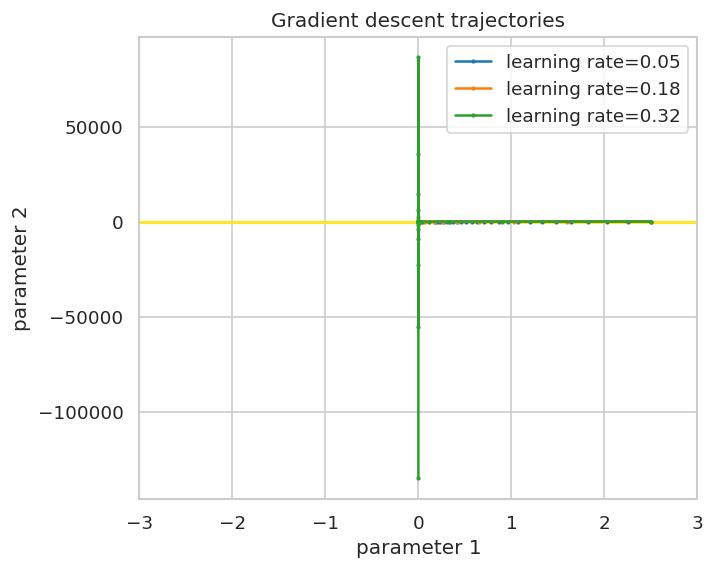

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_opt_f(p): return 0.5*(2*p[0]**2 + 8*p[1]**2)
def viz_opt_g(p): return np.array([2*p[0], 8*p[1]])
viz_opt_axis = np.linspace(-3, 3, 120)
viz_opt_X, viz_opt_Y = np.meshgrid(viz_opt_axis, viz_opt_axis)
viz_opt_Z = viz_opt_X**2 + 4*viz_opt_Y**2
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(viz_opt_X, viz_opt_Y, viz_opt_Z, levels=np.geomspace(0.05, 35, 18), cmap="viridis")
for viz_opt_eta, viz_opt_color in [(0.05, "tab:blue"), (0.18, "tab:orange"), (0.32, "tab:green")]:
    p = np.array([2.5, 2.0], dtype=float); path = [p.copy()]
    for _ in range(25):
        p = p-viz_opt_eta*viz_opt_g(p); path.append(p.copy())
    path = np.array(path)
    ax.plot(path[:,0], path[:,1], marker=".", ms=3, label=f"learning rate={viz_opt_eta}", color=viz_opt_color)
ax.set_xlabel("parameter 1"); ax.set_ylabel("parameter 2"); ax.legend(); ax.set_title("Gradient descent trajectories"); plt.show()

### Compare loss trajectories using pandas and Seaborn

Keep a training log rather than judging an optimizer from its final point alone. A loss curve can reveal slow convergence, oscillation, or instability. This deterministic toy example illustrates learning-rate behavior; real neural-network training also has stochastic batches, regularization, and changing gradient scales.

15_gradient_descent_and_newton_methods.ipynb:cell16:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,learning rate,step,loss
30,0.05,30,1.123100e-02
61,0.18,30,0.000000e+00
92,0.32,30,6.188649e+12
123,0.42,30,3.791754e+23


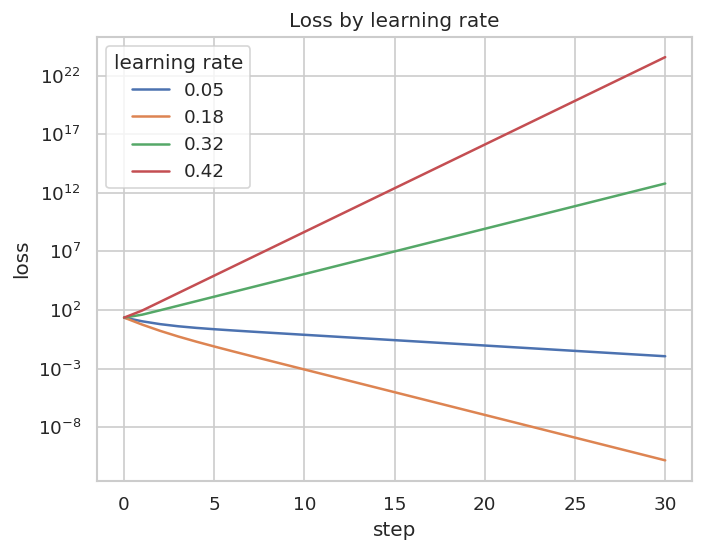

In [7]:
viz_loss_rows = []
for viz_loss_eta in [0.05, 0.18, 0.32, 0.42]:
    p = np.array([2.5, 2.0], dtype=float)
    for viz_loss_step in range(31):
        viz_loss_rows.append({"learning rate": str(viz_loss_eta), "step": viz_loss_step, "loss": viz_opt_f(p)})
        p = p-viz_loss_eta*viz_opt_g(p)
viz_loss_df = pd.DataFrame(viz_loss_rows)
sns.lineplot(data=viz_loss_df, x="step", y="loss", hue="learning rate")
plt.yscale("log"); plt.title("Loss by learning rate"); plt.show()
display(viz_loss_df.groupby("learning rate").tail(1).sort_values("learning rate").round(6))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Perform five gradient-descent steps on f(w)=(w-1)^2 with learning rate 0.1.

In [8]:
w = 4.0
for _ in range(5):
    w -= 0.1 * 2*(w-1)
print(w)

1.9830400000000001


### Exercise 2
Exercise 2: Explain why a linear solve is preferable to explicitly inverting a Hessian.

In [9]:
# A solver is typically faster and more numerically reliable than constructing the full inverse.

## Key takeaways
- Optimization minimizes a defined objective; the gradient indicates local steepest increase.
- Learning rate affects both convergence speed and stability.
- Second-order methods use curvature, but Hessians can be expensive or indefinite.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.